In [10]:
#%pip install numpy pandas matplotlib scipy statsmodels openpyxl pmdarima

In [11]:
# %% Importación de paquetes ============================

# Trabajar con rutas relativas en python
from pathlib import Path

# Módulos de numpy, pandas, matplotlib y scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, ccf, grangercausalitytests
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from scipy import stats

In [12]:

# %% Cargar bases de datos en python usando rutas relativas =========================

# Obtener la ruta del directorio actual de trabajo
BASE_DIR = Path.cwd()

# Rutas de las bases de datos
ruta_exp = BASE_DIR / "Demanda.xlsx" # Base de datos

In [13]:
# %% =========================
# carga de los datos
# # =============================

# Base de datos con la serie importada a python
#'''datos = pd.read_xlsx(ruta_exp, header=None)'''
# Usamos read_excel eliminando las primeras filas de metadatos definiendo header=2
datos = pd.read_excel(ruta_exp, header=2)

# Ver el tipo de objeto de la base de datos (Pandas.DataFrame)
print(type(datos))

<class 'pandas.core.frame.DataFrame'>


In [14]:
# %% Creación del índice temporal de las series de tiempo

# 1. Crear la columna única de fecha a partir de Año, Mes y Día
fecha_texto = datos['Date - Year'].astype(str) + '-' + datos['Date - Month'].astype(str) + '-' + datos['Date - Day'].astype(str)
datos['Date'] = pd.to_datetime(fecha_texto, format='%Y-%B-%d')

# 2. Reemplazar y eliminar las 3 columnas antiguas de año, mes y día
datos = datos.drop(columns=['Date - Year', 'Date - Month', 'Date - Day'])

# 3. Establecer la nueva columna de fecha como el índice del DataFrame
datos = datos.set_index('Date')

# El tipo de objeto de la base de datos sigue siendo Pandas.DataFrame
print(type(datos))

# Ver primeras y últimas observaciones de la base de datos con la nueva estructura
print(datos.head()) # Primeras observaciones
print(datos.tail()) # Últimas observaciones


# %% Creación de la serie de tiempo de "demanda"

# La nueva serie de tiempo se va a llamar "Demanda" para mantener compatibilidad con el resto de tu código
serie = datos["Suma de Demanda Energia SIN"].copy()
serie = pd.to_numeric(serie, errors="coerce")
serie = serie.dropna() # Borrar missing values

# Ver el principio y final de la serie de tiempo
print(serie.head())
print(serie.tail())

# El tipo de objeto de la base de datos ahora es un Pandas.Series
print(type(serie))

# Ver algunas estadísticas descriptivas de la serie de tiempo
print(serie.describe())

<class 'pandas.core.frame.DataFrame'>
            Suma de Demanda Energia SIN
Date                                   
2025-10-20                   236.585906
2025-10-21                   238.450828
2025-10-22                   239.883010
2025-10-23                   240.271402
2025-10-24                   241.451417
            Suma de Demanda Energia SIN
Date                                   
2026-10-11                   219.506259
2026-10-12                   219.453299
2026-10-13                   235.452010
2026-10-14                   244.366352
2026-10-15                   254.990340
Date
2025-10-20    236.585906
2025-10-21    238.450828
2025-10-22    239.883010
2025-10-23    240.271402
2025-10-24    241.451417
Name: Suma de Demanda Energia SIN, dtype: float64
Date
2026-10-11    219.506259
2026-10-12    219.453299
2026-10-13    235.452010
2026-10-14    244.366352
2026-10-15    254.990340
Name: Suma de Demanda Energia SIN, dtype: float64
<class 'pandas.core.series.Series'>
count 

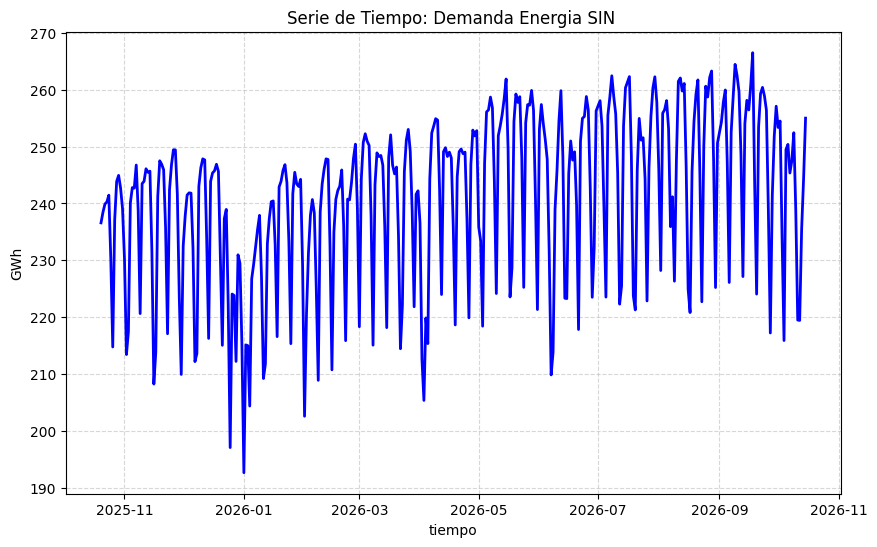

In [15]:

plt.figure(figsize=(10, 6))
plt.plot( datos['Suma de Demanda Energia SIN'], color='blue', linewidth=2)
plt.title('Serie de Tiempo: Demanda Energia SIN ')
plt.xlabel('tiempo')
plt.ylabel('GWh')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [16]:
# Ver algunas estadísticas descriptivas de la serie de tiempo
print(serie.describe())

count    361.000000
mean     241.092159
std       14.691408
min      192.685793
25%      232.248517
50%      244.352023
75%      252.240362
max      266.480643
Name: Suma de Demanda Energia SIN, dtype: float64


# Identificación 

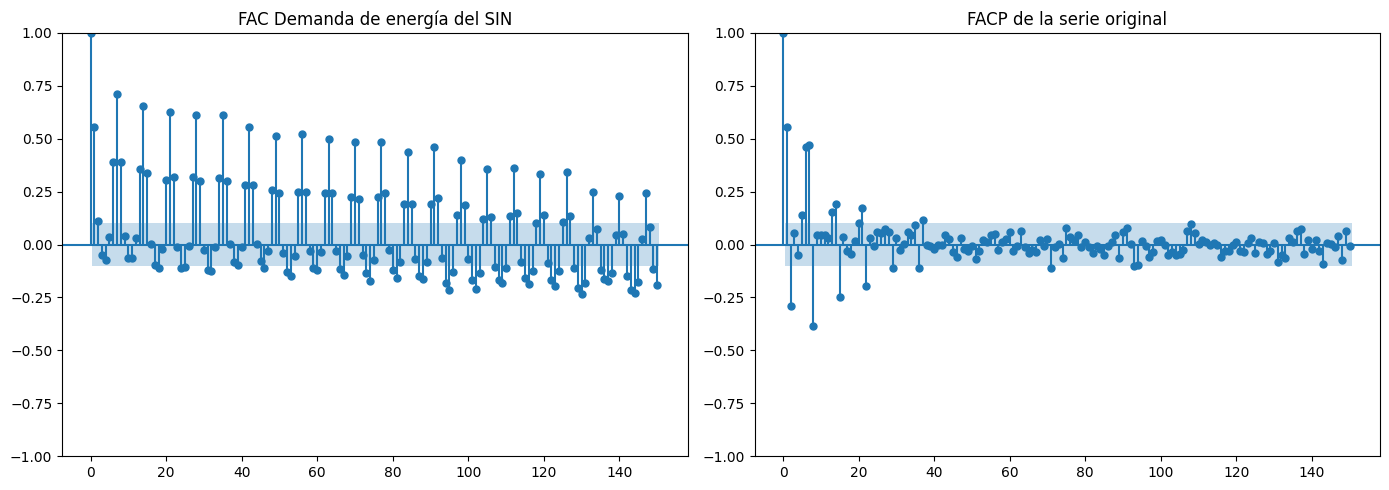

In [17]:
# %% FAC y FACP de la serie original

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    serie,
    lags=150,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC Demanda de energía del SIN")

plot_pacf(
    serie,
    lags=150,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de la serie original")

plt.tight_layout()
plt.show()

In [18]:
def evaluar_estacionariedad(serie, alpha=0.05):
    """
    Ejecuta y evalúa conjuntamente las pruebas ADF (Augmented Dickey-Fuller)
    y KPSS (Kwiatkowski-Phillips-Schmidt-Shin).
    """
    print("=" * 60)
    print("PRUEBAS DE ESTACIONARIEDAD")
    print("=" * 60)
    
    # 1.1 Test ADF (H0: La serie TIENE raíz unitaria / NO es estacionaria)
    adf_res = adfuller(serie.dropna(), autolag='AIC')
    p_adf = adf_res[1]
    
    # 1.2 Test KPSS (H0: La serie ES estacionaria alrededor de una constante)
    # catch_warnings ignora advertencias por p-valores fuera del rango tabulado
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_res = kpss(serie.dropna(), regression='c', nlags="auto")
    p_kpss = kpss_res[1]
    
    print(f"ADF Statistic: {adf_res[0]:.4f} | p-value: {p_adf:.4f}")
    print(f"KPSS Statistic: {kpss_res[0]:.4f} | p-value: {p_kpss:.4f}\n")
    
    # Diagnóstico combinado
    if p_adf < alpha and p_kpss >= alpha:
        print("-> CONCLUSIÓN: La serie es ESTACIONARIA (ADF rechaza H0, KPSS no rechaza H0).")
    elif p_adf >= alpha and p_kpss < alpha:
        print("-> CONCLUSIÓN: La serie NO ES ESTACIONARIA (Raíz unitaria presente). Se requiere diferenciar (d >= 1).")
    elif p_adf >= alpha and p_kpss >= alpha:
        print("-> CONCLUSIÓN: RESULTADO INCONCLUSO / Indiferente. Evaluar transformaciones o diferencias.")
    else:
        print("-> CONCLUSIÓN: Estacionariedad en tendencia (Difference stationary vs Trend stationary). Considere evaluar diferenciación o restar tendencia.")

# Ejecutar diagnóstico de estacionariedad
evaluar_estacionariedad(serie)

PRUEBAS DE ESTACIONARIEDAD
ADF Statistic: -2.4922 | p-value: 0.1174
KPSS Statistic: 3.0017 | p-value: 0.0100

-> CONCLUSIÓN: La serie NO ES ESTACIONARIA (Raíz unitaria presente). Se requiere diferenciar (d >= 1).


C:\Users\Kayak\AppData\Local\Temp\ipykernel_7836\1445543708.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(serie.dropna(), autolag='AIC')


Dados los resultados anteriores tanto la preuba ADF como la KPSS indican No estacionariedad. se justifica el uso de diferenciaciones, pero ¿cuantas?

In [19]:
# %% 1. FUNCIÓN PURE STATSMODELS: BÚSQUEDA ITERATIVA Y PREVENCIÓN DE SOBREDIFERENCIACIÓN
# =========================================================================

def determinar_diferenciacion_regular(serie, max_d=3, alpha=0.05):
    """
    Evalúa iterativamente d=0, 1, 2... calculando pruebas ADF, KPSS 
    y la desviación estándar para evitar el fenómeno de sobrediferenciación.
    """
    print("=" * 70)
    print("EVALUACIÓN ITERATIVA DE DIFERENCIACIÓN REGULAR (d)")
    print("=" * 70)
    
    resultados = []
    serie_diff = serie.copy().dropna()
    
    for d in range(max_d + 1):
        # 1. Test ADF (H0: No estacionaria)
        adf_p = adfuller(serie_diff, autolag='AIC')[1]
        
        # 2. Test KPSS (H0: Estacionaria)
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kpss_p = kpss(serie_diff, regression='c', nlags="auto")[1]
            
        # 3. Métricas de desviación y autocorrelación de primer retardo
        std_dev = serie_diff.std()
        acf_lag1 = serie_diff.autocorr(lag=1)
        
        # Clasificación del estado
        estacionaria = (adf_p < alpha) and (kpss_p >= alpha)
        
        resultados.append({
            'd': d,
            'ADF p-value': adf_p,
            'KPSS p-value': kpss_p,
            'Std Dev': std_dev,
            'ACF Lag 1': acf_lag1,
            'Estacionaria': "SÍ" if estacionaria else "NO"
        })
        
        # Preparar siguiente orden de diferencia: ΔY_t = Y_t - Y_{t-1}
        serie_diff = serie_diff.diff().dropna()
        
    df_res = pd.DataFrame(resultados)
    print(df_res.to_string(index=False))
    
    # Regla de selección recomendada
    # Priorizar el menor 'd' que logre estacionariedad sin disparar la desviación estándar
    cand = df_res[df_res['Estacionaria'] == "SÍ"]
    
    if not cand.empty:
        best_d = cand.iloc[0]['d']
        print(f"\n-> RECOMENDACIÓN: Usar d = {int(best_d)}")
    else:
        # Si ninguna combinación estricta da SÍ, elegir donde la varianza disminuye y ADF aprueba
        best_d = df_res[df_res['ADF p-value'] < alpha]['d'].min()
        print(f"\n-> RECOMENDACIÓN EVALUADA POR ADF: Usar d = {int(best_d) if not pd.isna(best_d) else 1}")
        
    print("\n* NOTA SOBREDIFERENCIACIÓN:")
    print("  - Si Std Dev AUMENTA con respecto al orden anterior, hay sobrediferenciación.")
    print("  - Si ACF Lag 1 es menor a -0.5, la serie ha sido sobrediferenciada.\n")
    
    return df_res

# Ejecutar la evaluación iterativa sobre la serie
res_d = determinar_diferenciacion_regular(serie)

EVALUACIÓN ITERATIVA DE DIFERENCIACIÓN REGULAR (d)


C:\Users\Kayak\AppData\Local\Temp\ipykernel_7836\1562719655.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(serie_diff, autolag='AIC')[1]
C:\Users\Kayak\AppData\Local\Temp\ipykernel_7836\1562719655.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(serie_diff, autolag='AIC')[1]
C:\Users\Kayak\AppData\Local\Temp\ipykernel_7836\15627

 d  ADF p-value  KPSS p-value   Std Dev  ACF Lag 1 Estacionaria
 0 1.173874e-01      0.010000 14.691408   0.556983           NO
 1 8.271119e-10      0.100000 13.838646   0.004989           SÍ
 2 2.248849e-19      0.041667 19.540963  -0.334766           NO
 3 1.047219e-25      0.100000 31.971899  -0.530013           SÍ

-> RECOMENDACIÓN: Usar d = 1

* NOTA SOBREDIFERENCIACIÓN:
  - Si Std Dev AUMENTA con respecto al orden anterior, hay sobrediferenciación.
  - Si ACF Lag 1 es menor a -0.5, la serie ha sido sobrediferenciada.



C:\Users\Kayak\AppData\Local\Temp\ipykernel_7836\1562719655.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(serie_diff, autolag='AIC')[1]


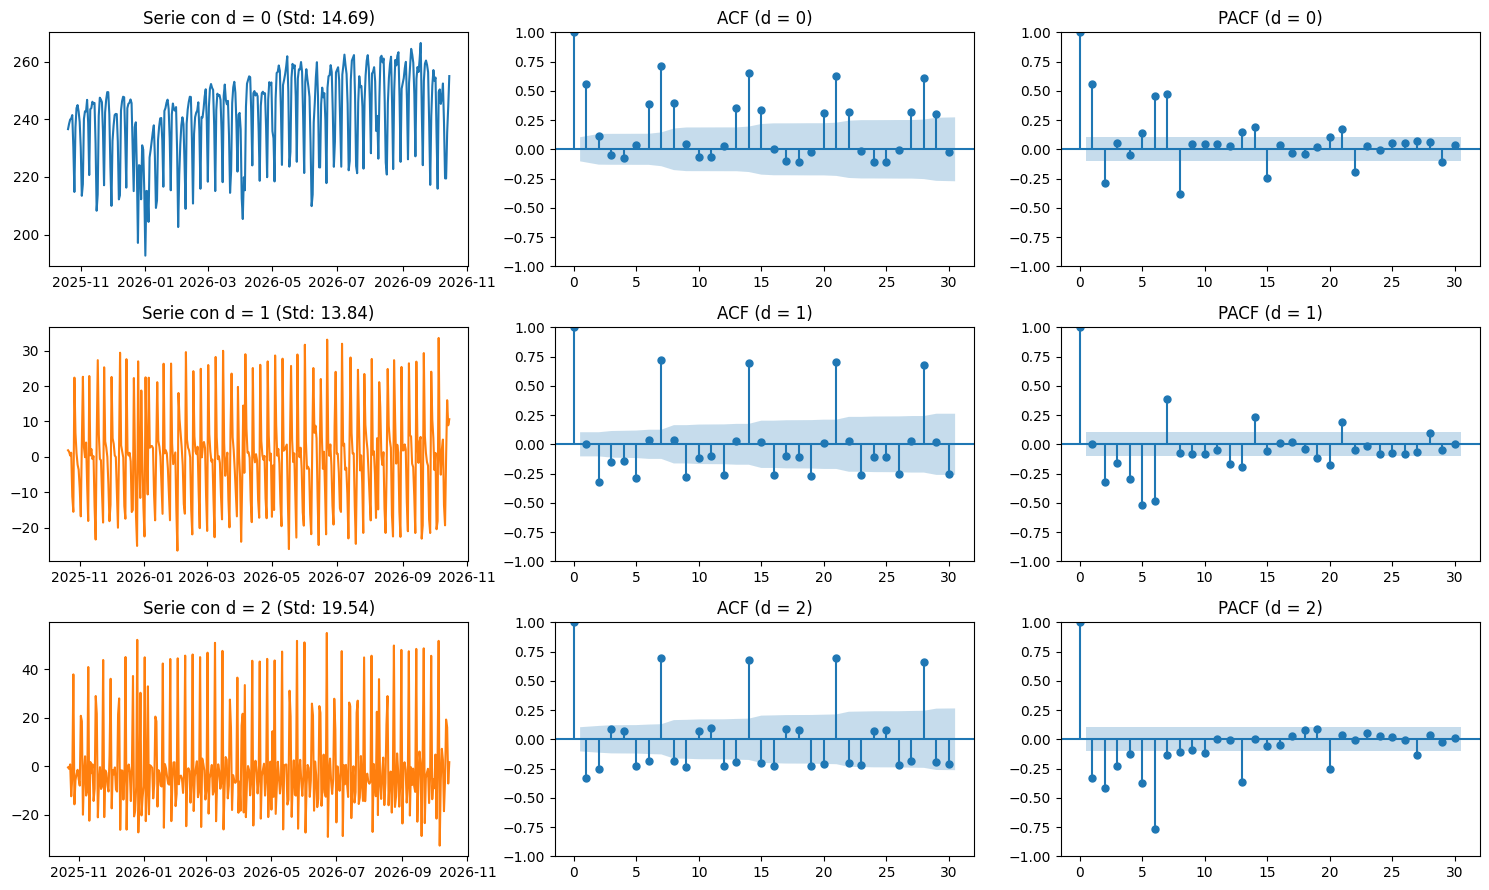

In [20]:
def graficar_efecto_diferenciacion(serie, d_max=2):
    """
    Muestra visualmente cómo cambia la serie y sus autocorrelaciones 
    a medida que se aplican diferenciaciones.
    """
    fig, axes = plt.subplots(d_max + 1, 3, figsize=(15, 3 * (d_max + 1)))
    
    s_temp = serie.copy().dropna()
    
    for i in range(d_max + 1):
        # Gráfico de tiempo
        axes[i, 0].plot(s_temp, color='tab:blue' if i==0 else 'tab:orange')
        axes[i, 0].set_title(f"Serie con d = {i} (Std: {s_temp.std():.2f})")
        
        # ACF
        plot_acf(s_temp, ax=axes[i, 1], lags=30, title=f"ACF (d = {i})")
        
        # PACF
        plot_pacf(s_temp, ax=axes[i, 2], lags=30, title=f"PACF (d = {i})")
        
        s_temp = s_temp.diff().dropna()
        
    plt.tight_layout()
    plt.show()

# Graficar la serie original, d=1 y d=2 para comparación visual
graficar_efecto_diferenciacion(serie, d_max=2)

He ahí que es deseable diferenciar una vez la serie.

In [21]:
seriedif = serie.diff().dropna()

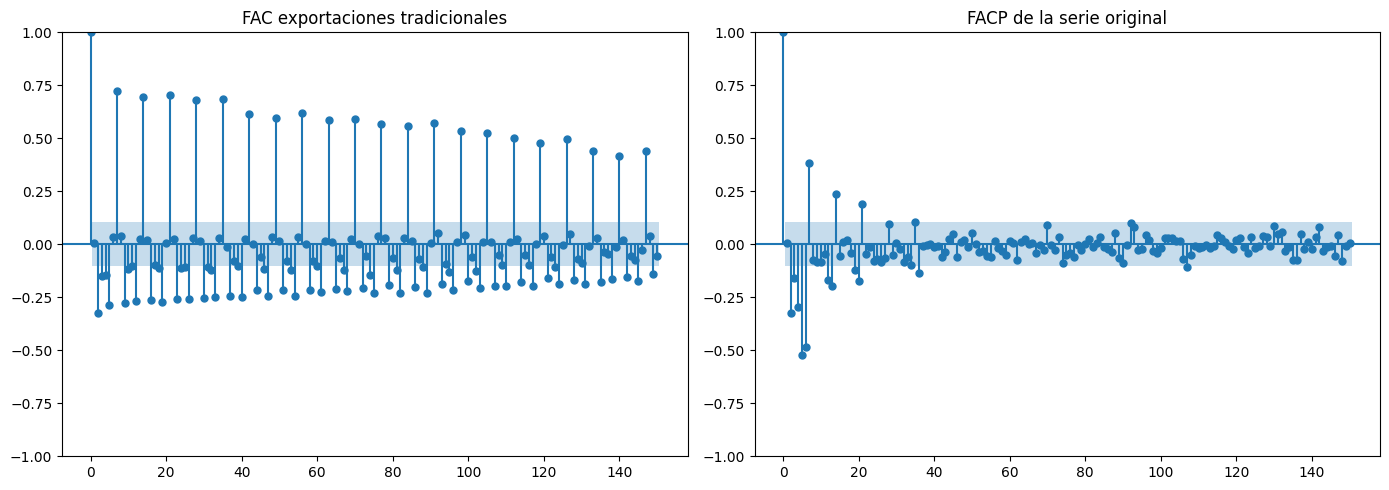

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    seriedif,
    lags=150,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC exportaciones tradicionales")

plot_pacf(
    seriedif,
    lags=150,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de la serie original")

plt.tight_layout()
plt.show()

grafiacmente no se ve tendencia pero para estar seguros:

In [23]:
# %% =========================================================================
# 2. PRUEBAS Y DIAGNÓSTICO DE TENDENCIA
# =========================================================================

def evaluar_tendencia(seriedif, alpha=0.05):
    """
    Evalúa la presencia de tendencia estocástica o determinista mediante
    Kendall Tau (Prueba no paramétrica) y Regresión Lineal OLS sobre el tiempo.
    """
    print("\n" + "=" * 60)
    print("PRUEBAS DE TENDENCIA")
    print("=" * 60)
    
    y = seriedif.dropna().values
    t = np.arange(len(y))
    
    # 2.1 Test de correlación de Kendall (Mann-Kendall aproximado)
    tau, p_kendall = stats.kendalltau(t, y)
    
    # 2.2 Regresión determinista lineal
    slope, intercept, r_value, p_reg, std_err = stats.linregress(t, y)
    
    print(f"Kendall Tau: {tau:.4f} | p-value: {p_kendall:.4f}")
    print(f"Pendiente OLS: {slope:.6f} | R2: {r_value**2:.4f} | p-value: {p_reg:.4f}\n")
    
    if p_kendall < alpha or p_reg < alpha:
        direccion = "creciente" if slope > 0 else "decreciente"
        print(f"-> CONCLUSIÓN: Existe una TENDENCIA significativa ({direccion}).")
    else:
        print("-> CONCLUSIÓN: No se detecta tendencia determinista significativa.")

# Ejecutar diagnóstico de tendencia
evaluar_tendencia(serie)


PRUEBAS DE TENDENCIA
Kendall Tau: 0.3149 | p-value: 0.0000
Pendiente OLS: 0.053690 | R2: 0.1454 | p-value: 0.0000

-> CONCLUSIÓN: Existe una TENDENCIA significativa (creciente).


adicionalmente vamos a ver si hay estacionalidad

PRUEBAS DE ESTACIONALIDAD (Periodo asumido: 7)
Fuerza de la Estacionalidad (Fs): 0.8449
-> CONCLUSIÓN: Existe una ESTACIONALIDAD FUERTE en la serie (Fs > 0.6).
Kruskal-Wallis Stat: 163.7491 | p-value: 0.0000
-> CONCLUSIÓN: Diferencias estacionales altamente SIGNIFICATIVAS entre grupos.



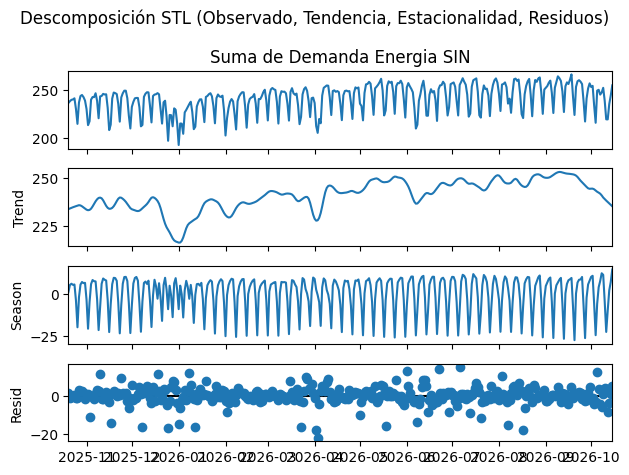

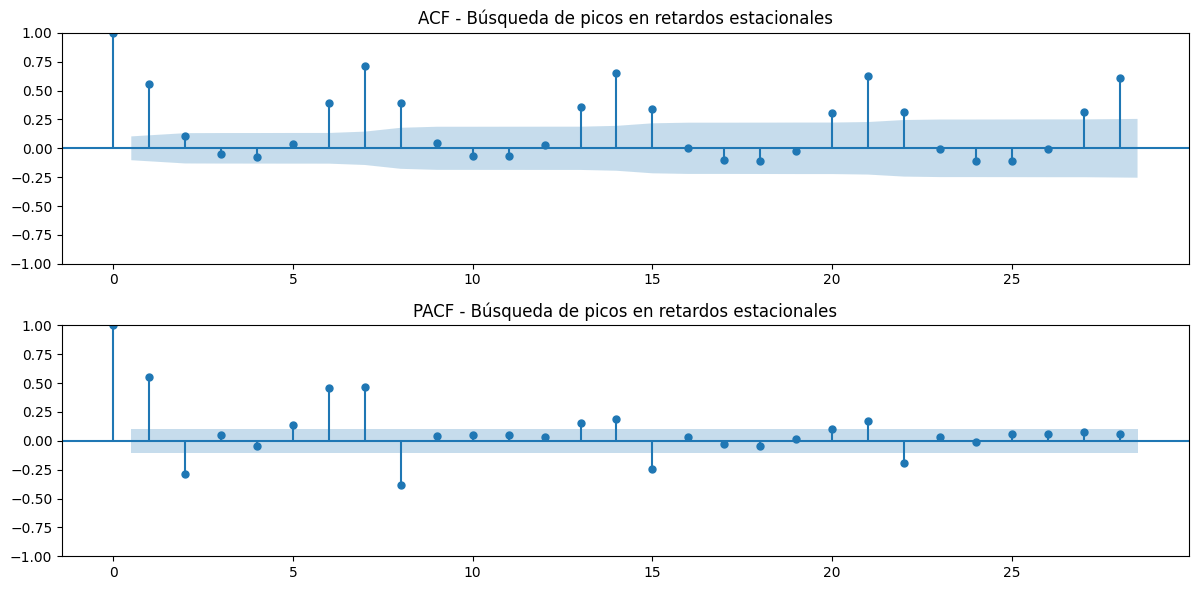

por metodo gráfico podría ser un ARIMA(3,1,3)(1,1,1)[7] o ARIMA(2,1,2)(1,1,1)[7]


In [24]:
def evaluar_estacionalidad(seriedif, periodo=7, alpha=0.05):
    """
    Evalúa la presencia de estacionalidad mediante:
    1. Descomposición STL y cálculo de la Fuerza de Estacionalidad (Fs).
    2. Prueba no paramétrica de Kruskal-Wallis entre ciclos.
    3. Inspección gráfica de descomposición STL y funciones ACF/PACF.
    """
    print("=" * 60)
    print(f"PRUEBAS DE ESTACIONALIDAD (Periodo asumido: {periodo})")
    print("=" * 60)
    
    df_clean = serie.dropna()
    
    # 3.1 Descomposición STL
    stl_fit = STL(df_clean, period=periodo).fit()
    
    # Cálculo de la Fuerza de la Estacionalidad (Fs)
    # Fs = max(0, 1 - Var(Remanente) / Var(Estacional + Remanente))
    var_resid = np.var(stl_fit.resid)
    var_seas_resid = np.var(stl_fit.seasonal + stl_fit.resid)
    fuerza_estacional = max(0, 1 - (var_resid / var_seas_resid))
    
    print(f"Fuerza de la Estacionalidad (Fs): {fuerza_estacional:.4f}")
    if fuerza_estacional > 0.6:
        print("-> CONCLUSIÓN: Existe una ESTACIONALIDAD FUERTE en la serie (Fs > 0.6).")
    elif fuerza_estacional > 0.3:
        print("-> CONCLUSIÓN: Existe una ESTACIONALIDAD MODERADA en la serie.")
    else:
        print("-> CONCLUSIÓN: Estacionalidad DÉBIL o no significativa.")
        
    # 3.2 Prueba de Kruskal-Wallis entre grupos según el tipo de índice
    if isinstance(df_clean.index, pd.DatetimeIndex):
        if periodo == 7:      # Datos diarios agrupados por día de la semana
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.dayofweek)]
        elif periodo == 12:   # Datos mensuales agrupados por mes del año
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.month)]
        elif periodo == 24:   # Datos horarios agrupados por hora del día
            grupos = [group.values for _, group in df_clean.groupby(df_clean.index.hour)]
        else:
            grupos = None
            
        if grupos and len(grupos) > 1:
            kw_stat, p_kw = stats.kruskal(*grupos)
            print(f"Kruskal-Wallis Stat: {kw_stat:.4f} | p-value: {p_kw:.4f}")
            if p_kw < alpha:
                print("-> CONCLUSIÓN: Diferencias estacionales altamente SIGNIFICATIVAS entre grupos.\n")
            else:
                print("-> CONCLUSIÓN: No se detectan diferencias significativas entre grupos.\n")
                
    # 3.3 Gráficos: STL por un lado, ACF/PACF por otro
    # Descomposición STL
    fig_stl = stl_fit.plot()
    fig_stl.suptitle("Descomposición STL (Observado, Tendencia, Estacionalidad, Residuos)", fontsize=12)
    fig_stl.tight_layout()
    plt.show()

    # Correlogramas ACF y PACF
    fig, axes = plt.subplots(2, 1, figsize=(12, 6))
    plot_acf(df_clean, lags=periodo * 4, ax=axes[0], title="ACF - Búsqueda de picos en retardos estacionales")
    plot_pacf(df_clean, lags=periodo * 4, ax=axes[1], title="PACF - Búsqueda de picos en retardos estacionales")
    plt.tight_layout()
    plt.show()


# Ejecutar prueba (Ajustar periodo: 7 para diario, 12 para mensual, 24 para horario)
evaluar_estacionalidad(seriedif, periodo=7)
print(f"por metodo gráfico podría ser un ARIMA(3,1,3)(1,1,1)[7] o ARIMA(2,1,2)(1,1,1)[7]")

In [25]:
#por metodo gráfico podría ser un ARIMA(3,1,3)(1,1,1)[7] o ARIMA(2,1,2)(1,1,1)[7]


De esta forma existe estacionalidad diaria. (Se realizaron pruebas con periodicidad mensual periodo= 12 y semanal periodo =52 sin hallar una estacionalidad fuerte)
<b>
con la información anterior se puede pasar a identificar los ordenes del modelo, sabiendo que es un SARIMA


In [26]:
# %% =========================================================================
# IDENTIFICACIÓN AUTOMÁTICA DE ÓRDENES CON PMDARIMA
# =========================================================================

from pmdarima import auto_arima

# Ejecutar la búsqueda del modelo óptimo
modelo_auto = auto_arima(
    serie,
    d=1,                      # Diferencia regular previa (o None si quieres que la estime)
    D=1,                      # Diferencia estacional previa (o None si quieres que la estime)
    m=7,                      # Período estacional s (ej. 7 para diario)
    seasonal=True,            # Habilitar componente SARIMA
    start_p=0, max_p=3,       # Rango para p
    start_q=0, max_q=3,       # Rango para q
    start_P=0, max_P=2,       # Rango para P
    start_Q=0, max_Q=2,       # Rango para Q
    information_criterion='aic', # Métrica a minimizar
    stepwise=True,            # Algoritmo Stepwise de Hyndman-Khandakar (más rápido)
    trace=True,               # Muestra cada modelo probado en la consola
    error_action='ignore',
    suppress_warnings=True
)

# Imprimir el resumen del modelo seleccionado
print("\n" + "=" * 60)
print("MEJOR MODELO SELECCIONADO POR AIC:")
print("=" * 60)
print(modelo_auto.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[7]             : AIC=2635.944, Time=0.06 sec
 ARIMA(1,1,0)(1,1,0)[7]             : AIC=2553.227, Time=0.25 sec
 ARIMA(0,1,1)(0,1,1)[7]             : AIC=inf, Time=0.43 sec
 ARIMA(1,1,0)(0,1,0)[7]             : AIC=2632.379, Time=0.10 sec
 ARIMA(1,1,0)(2,1,0)[7]             : AIC=2500.746, Time=0.46 sec
 ARIMA(1,1,0)(2,1,1)[7]             : AIC=inf, Time=1.35 sec
 ARIMA(1,1,0)(1,1,1)[7]             : AIC=inf, Time=0.64 sec
 ARIMA(0,1,0)(2,1,0)[7]             : AIC=2500.988, Time=0.27 sec
 ARIMA(2,1,0)(2,1,0)[7]             : AIC=2491.729, Time=0.51 sec
 ARIMA(2,1,0)(1,1,0)[7]             : AIC=2543.402, Time=0.35 sec
 ARIMA(2,1,0)(2,1,1)[7]             : AIC=inf, Time=1.47 sec
 ARIMA(2,1,0)(1,1,1)[7]             : AIC=inf, Time=0.94 sec
 ARIMA(3,1,0)(2,1,0)[7]             : AIC=2483.705, Time=0.68 sec
 ARIMA(3,1,0)(1,1,0)[7]             : AIC=2533.795, Time=0.43 sec
 ARIMA(3,1,0)(2,1,1)[7]             : AIC=inf, Time=2.11 s

In [27]:
# %% =========================================================================
# 3. BÚSQUEDA MANUAL DE BUCLE (GRID SEARCH) CON STATSMODELS
# =========================================================================

import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Definir rangos de búsqueda
p_range = range(0, 3)
q_range = range(0, 3)
P_range = range(0, 2)
Q_range = range(0, 2)

d_fijo = 1
D_fijo = 1
s_fijo = 7

mejores_resultados = []

for p, q, P, Q in itertools.product(p_range, q_range, P_range, Q_range):
    try:
        mod = SARIMAX(
            serie,
            order=(p, d_fijo, q),
            seasonal_order=(P, D_fijo, Q, s_fijo),
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        res = mod.fit(disp=False)
        mejores_resultados.append({
            'order': (p, d_fijo, q),
            'seasonal_order': (P, D_fijo, Q, s_fijo),
            'AIC': res.aic,
            'BIC': res.bic
        })
    except Exception:
        continue

# Convertir a DataFrame y ordenar por menor AIC
df_grid = pd.DataFrame(mejores_resultados).sort_values(by='AIC').reset_index(drop=True)

print("Top 5 modelos con menor AIC:")
print(df_grid.head())
print(f"por selección manual el mejor modelo es el ARIMA(1, 1, 2)(0, 1, 1, )[7] con un AIC  de 2305.754462  y un BIC de 2324.943114, se ve que aumentar los ordenes p,q,P,Q no disminuye los criterios de información")

c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\s

Top 5 modelos con menor AIC:
       order seasonal_order          AIC          BIC
0  (1, 1, 2)   (0, 1, 1, 7)  2305.754462  2324.943114
1  (2, 1, 2)   (0, 1, 1, 7)  2306.246233  2329.272616
2  (1, 1, 2)   (1, 1, 1, 7)  2307.754236  2330.780619
3  (2, 1, 2)   (1, 1, 1, 7)  2308.245254  2335.109367
4  (2, 1, 1)   (0, 1, 1, 7)  2311.130798  2330.334006
por selección manual el mejor modelo es el ARIMA(1, 1, 2)(0, 1, 1, )[7] con un AIC  de 2305.754462  y un BIC de 2324.943114, se ve que aumentar los ordenes p,q,P,Q no disminuye los criterios de información


He ahí hay 4 candidatos:
<br>
ARIMA(1, 1, 2)(0, 1, 1) [7] 
<br>ARIMA(3,1,0)(2,1,0)[7] 
<br>ARIMA (3,1,3)(1,1,1)[7] 
<br>ARIMA(2,1,2)(1,1,1)[7]
<br>Corramoslos todos y veamos cuál tiene mejor criterio de información.

In [28]:
# Definición de la lista de modelos candidatos
candidatos = [
    {"order": (1, 1, 2), "seasonal_order": (0, 1, 1, 7)},
    {"order": (3, 1, 0), "seasonal_order": (2, 1, 0, 7)},
    {"order": (3, 1, 3), "seasonal_order": (1, 1, 1, 7)},
    {"order": (2, 1, 2), "seasonal_order": (1, 1, 1, 7)},
]

resultados = []

print("=" * 70)
print("AJUSTANDO Y EVALUANDO MODELOS CANDIDATOS...")
print("=" * 70)

for cand in candidatos:
    order = cand["order"]
    seasonal_order = cand["seasonal_order"]
    nombre_modelo = f"SARIMA{order}{seasonal_order}"
    
    try:
        # Ajuste del modelo SARIMAX
        modelo = SARIMAX(
            serie,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fit_res = modelo.fit(disp=False)
        
        resultados.append({
            "Modelo": nombre_modelo,
            "AIC": fit_res.aic,
            "BIC": fit_res.bic,
            "Log-Likelihood": fit_res.llf
        })
        print(f"  ✓ {nombre_modelo:<30} | AIC: {fit_res.aic:10.2f} | BIC: {fit_res.bic:10.2f}")
        
    except Exception as e:
        print(f"  ✗ Error al ajustar {nombre_modelo}: {e}")

# Convertir a DataFrame y ordenar
df_resultados = pd.DataFrame(resultados)

df_por_aic = df_resultados.sort_values(by="AIC").reset_index(drop=True)
df_por_bic = df_resultados.sort_values(by="BIC").reset_index(drop=True)

print("\n" + "=" * 70)
print("RESUMEN COMPARATIVO FINAL")
print("=" * 70)
print(df_resultados.to_string(index=False))

print("\n" + "-" * 70)
print(f"🏆 MEJOR MODELO SEGÚN AIC: {df_por_aic.iloc[0]['Modelo']} (AIC = {df_por_aic.iloc[0]['AIC']:.2f})")
print(f"🏆 MEJOR MODELO SEGÚN BIC: {df_por_bic.iloc[0]['Modelo']} (BIC = {df_por_bic.iloc[0]['BIC']:.2f})")
print("-" * 70)

AJUSTANDO Y EVALUANDO MODELOS CANDIDATOS...


c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


  ✓ SARIMA(1, 1, 2)(0, 1, 1, 7)    | AIC:    2305.75 | BIC:    2324.94


c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


  ✓ SARIMA(3, 1, 0)(2, 1, 0, 7)    | AIC:    2365.60 | BIC:    2388.50


c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-

  ✓ SARIMA(3, 1, 3)(1, 1, 1, 7)    | AIC:    2303.29 | BIC:    2337.80
  ✓ SARIMA(2, 1, 2)(1, 1, 1, 7)    | AIC:    2308.25 | BIC:    2335.11

RESUMEN COMPARATIVO FINAL
                     Modelo         AIC         BIC  Log-Likelihood
SARIMA(1, 1, 2)(0, 1, 1, 7) 2305.754462 2324.943114    -1147.877231
SARIMA(3, 1, 0)(2, 1, 0, 7) 2365.595070 2388.497737    -1176.797535
SARIMA(3, 1, 3)(1, 1, 1, 7) 2303.287128 2337.800424    -1142.643564
SARIMA(2, 1, 2)(1, 1, 1, 7) 2308.245254 2335.109367    -1147.122627

----------------------------------------------------------------------
🏆 MEJOR MODELO SEGÚN AIC: SARIMA(3, 1, 3)(1, 1, 1, 7) (AIC = 2303.29)
🏆 MEJOR MODELO SEGÚN BIC: SARIMA(1, 1, 2)(0, 1, 1, 7) (BIC = 2324.94)
----------------------------------------------------------------------


por parsimonia se eligirá el modelo SARIMA(1,1,2)(0,1,1,7)
<br>
A continuación se realiza la estimación del modelo:


In [41]:
# %% =========================================================================
# ESTIMACIÓN Y DIAGNÓSTICO DEL MODELO SARIMA(1,1,2)(0,1,1)[7] CON TENDENCIA
# =========================================================================

# 1. Definición y ajuste del modelo SARIMA
# Nota sobre la tendencia: 
# - 'trend="c"' agrega un término constante en la serie diferenciada (deriva/drift lineal en el nivel).
# - Si d=1 y D=1 ya absorben completamente la tendencia, se puede cambiar a 'trend="n"'.
modelo = SARIMAX(
    serie,
    order=(1, 1, 2),
    seasonal_order=(0, 1, 1, 7),
    trend='n',  # 'c' para constante/drift; 't' para tendencia determinista lineal directa
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado = modelo.fit(disp=False)

# 2. Resumen completo de la estimación (Coeficientes, P-valores, AIC, BIC)
print("=" * 80)
print("RESUMEN DE ESTIMACIÓN: SARIMA(1,1,2)(0,1,1)[7]")
print("=" * 80)
print(resultado.summary())


c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


RESUMEN DE ESTIMACIÓN: SARIMA(1,1,2)(0,1,1)[7]
                                      SARIMAX Results                                      
Dep. Variable:         Suma de Demanda Energia SIN   No. Observations:                  361
Model:             SARIMAX(1, 1, 2)x(0, 1, [1], 7)   Log Likelihood               -1147.877
Date:                             Wed, 21 Oct 2026   AIC                           2305.754
Time:                                     20:20:26   BIC                           2324.943
Sample:                                 10-20-2025   HQIC                          2313.398
                                      - 10-15-2026                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4782      0.113      4.241      0.000     

Con lo anterior resulta evidente que hay que tratar de encontrar otro modelo, ya que la parte MA 2 resulta no significativo

In [33]:
# %% =========================================================================
# ESTIMACIÓN Y DIAGNÓSTICO DEL MODELO SARIMA(1,1,2)(0,1,1)[7] CON TENDENCIA
# =========================================================================

# 1. Definición y ajuste del modelo SARIMA
# Nota sobre la tendencia: 
# - 'trend="c"' agrega un término constante en la serie diferenciada (deriva/drift lineal en el nivel).
# - Si d=1 y D=1 ya absorben completamente la tendencia, se puede cambiar a 'trend="n"'.
modelo = SARIMAX(
    serie,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 7),
    trend='n',  # 'c' para constante/drift; 't' para tendencia determinista lineal directa
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado = modelo.fit(disp=False)

# 2. Resumen completo de la estimación (Coeficientes, P-valores, AIC, BIC)
print("=" * 80)
print("RESUMEN DE ESTIMACIÓN: SARIMA(1,1,1)(0,1,1)[7]")
print("=" * 80)
print(resultado.summary())
"""
# 3. Diagnóstico gráfico de residuos (Distribución, QQ-plot, Autocorrelación)
fig = resultado.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

# 4. PRUEBAS DE HIPÓTESIS SOBRE LOS RESIDUOS
print("\n" + "=" * 60)
print("VERIFICACIÓN DE RUIDO BLANCO (PRUEBA DE LJUNG-BOX)")
print("=" * 60)

# Ljung-Box para evaluar autocorrelación en los retardos estacionales (7, 14, 21)
lb_test = acorr_ljungbox(resultado.resid.dropna(), lags=[7, 14, 21], return_df=True)
print(lb_test)

# Interpretación rápida del test
p_val_min = lb_test['lb_pvalue'].min()
if p_val_min > 0.05:
    print(f"\n-> CONCLUSIÓN: Los residuos cumplen con la propiedad de RUIDO BLANCO (p-valor min = {p_val_min:.4f} > 0.05). El modelo captura adecuadamente la estructura temporal.")
else:
    print(f"\n-> ADVERTENCIA: Queda estructura en los residuos (p-valor min = {p_val_min:.4f} <= 0.05). Considera probar con trend='n' u otro parámetro de AR/MA.")
"""

c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Kayak\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


RESUMEN DE ESTIMACIÓN: SARIMA(1,1,1)(0,1,1)[7]
                                     SARIMAX Results                                     
Dep. Variable:       Suma de Demanda Energia SIN   No. Observations:                  361
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 7)   Log Likelihood               -1153.311
Date:                           Wed, 21 Oct 2026   AIC                           2314.622
Time:                                   19:54:51   BIC                           2329.985
Sample:                               10-20-2025   HQIC                          2320.741
                                    - 10-15-2026                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6314      0.037     17.099      0.000       0.559       0.

'\n# 3. Diagnóstico gráfico de residuos (Distribución, QQ-plot, Autocorrelación)\nfig = resultado.plot_diagnostics(figsize=(12, 8))\nplt.tight_layout()\nplt.show()\n\n# 4. PRUEBAS DE HIPÓTESIS SOBRE LOS RESIDUOS\nprint("\n" + "=" * 60)\nprint("VERIFICACIÓN DE RUIDO BLANCO (PRUEBA DE LJUNG-BOX)")\nprint("=" * 60)\n\n# Ljung-Box para evaluar autocorrelación en los retardos estacionales (7, 14, 21)\nlb_test = acorr_ljungbox(resultado.resid.dropna(), lags=[7, 14, 21], return_df=True)\nprint(lb_test)\n\n# Interpretación rápida del test\np_val_min = lb_test[\'lb_pvalue\'].min()\nif p_val_min > 0.05:\n    print(f"\n-> CONCLUSIÓN: Los residuos cumplen con la propiedad de RUIDO BLANCO (p-valor min = {p_val_min:.4f} > 0.05). El modelo captura adecuadamente la estructura temporal.")\nelse:\n    print(f"\n-> ADVERTENCIA: Queda estructura en los residuos (p-valor min = {p_val_min:.4f} <= 0.05). Considera probar con trend=\'n\' u otro parámetro de AR/MA.")\n'

PASO 3: validación de supuestos.


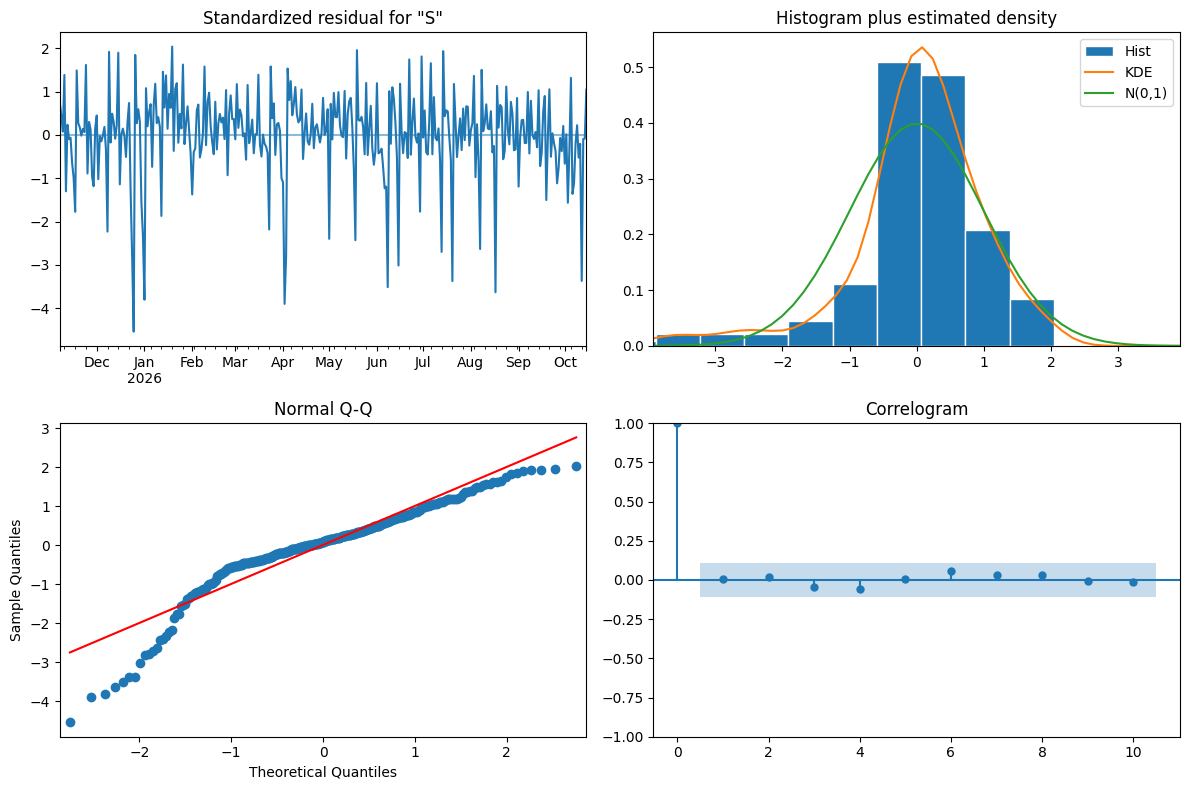

 hay indicios de no noramlidad y heterocedasticidad


In [42]:
#primera aproximación
fig = resultado.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()
print(f" hay indicios de no noramlidad y heterocedasticidad")

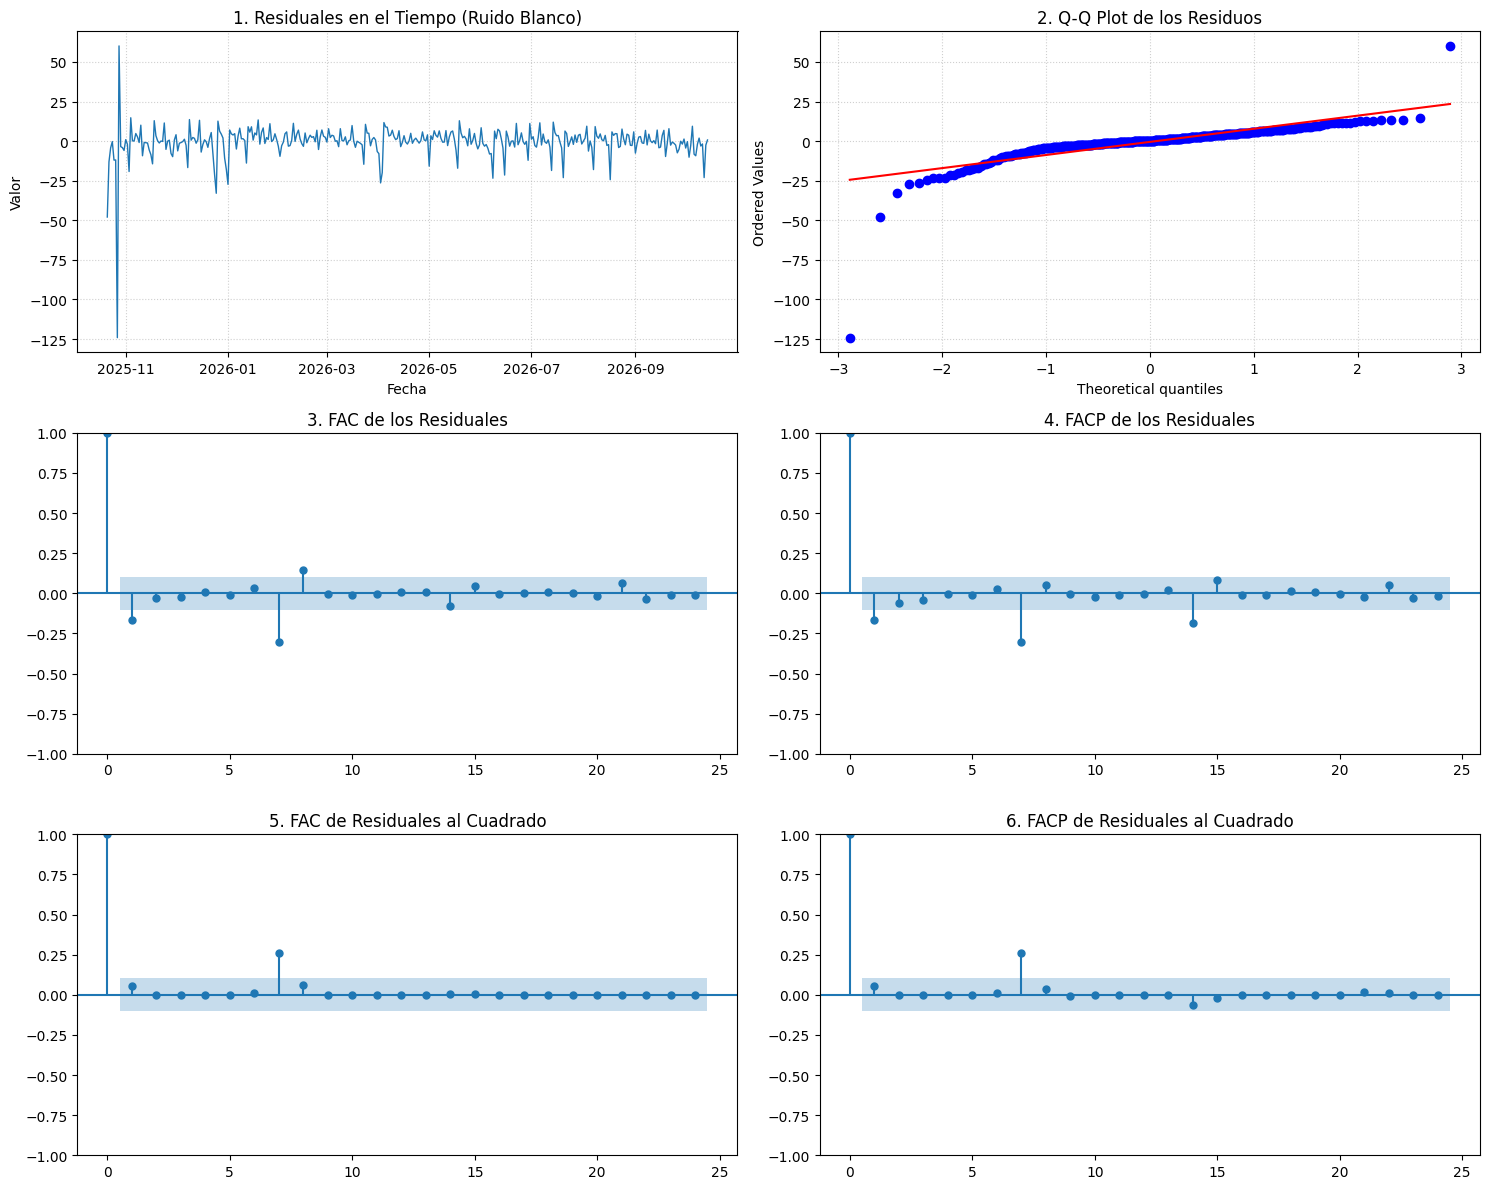

In [38]:
# 1. Extracción de residuales limpios
residuales = resultado.resid.dropna()

# 2. Creación del panel único de gráficas (3 filas x 2 columnas)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# --- Gráfica 1: Serie de tiempo de los residuales ---
axes[0, 0].plot(residuales.iloc[1:-1], color='tab:blue', linewidth=1)
axes[0, 0].set_title("1. Residuales en el Tiempo (Ruido Blanco)")
axes[0, 0].set_xlabel("Fecha")
axes[0, 0].set_ylabel("Valor")
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# --- Gráfica 2: Q-Q Plot de Normalidad ---
probplot(residuales.iloc[1:-1], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("2. Q-Q Plot de los Residuos")
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# --- Gráfica 3: FAC de los residuales ---
plot_acf(
    residuales,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. FAC de los Residuales")

# --- Gráfica 4: FACP de los residuales ---
plot_pacf(
    residuales,
    lags=24,
    alpha=0.05,
    ax=axes[1, 1]
)
axes[1, 1].set_title("4. FACP de los Residuales")

# --- Gráfica 5: FAC de los residuales al cuadrado (Efectos ARCH) ---
plot_acf(
    residuales**2,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[2, 0]
)
axes[2, 0].set_title("5. FAC de Residuales al Cuadrado")

# --- Gráfica 6: FACP de los residuales al cuadrado (Efectos ARCH) ---
plot_pacf(
    residuales**2,
    lags=24,
    alpha=0.05,
    ax=axes[2, 1]
)
axes[2, 1].set_title("6. FACP de Residuales al Cuadrado")

plt.tight_layout()
plt.show()



In [40]:
# %% =========================================================================
# PRUEBAS ESTADÍSTICAS FORMALES Y RESUMEN DE DIAGNÓSTICO
# =========================================================================

from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera

alpha = 0.05  # Nivel de significancia (5%)

print("=" * 75)
print("              DIAGNÓSTICO FORMAL DE SUPUESTOS ECONOMÉTRICOS")
print("=" * 75)

# -------------------------------------------------------------------------
# 1. PRUEBA DE LJUNG-BOX (Autocorrelación)
# -------------------------------------------------------------------------
print("\n1. PRUEBA DE LJUNG-BOX (Autocorrelación / Independencia)")
print("-" * 75)

ljung_box = acorr_ljungbox(residuales, lags=[6, 12, 18, 24], return_df=True)

# Mostrar resumen compacto en lugar de la tabla extendida
for lag, row in ljung_box.iterrows():
    stat = row['lb_stat']
    pval = row['lb_pvalue']
    print(f"   Lag {lag:2d} -> Estadístico Q: {stat:8.4f} | p-valor: {pval:.4f}")

min_p_lb = ljung_box['lb_pvalue'].min()

if min_p_lb > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de independencia (Ruido Blanco).")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de independencia.")

# -------------------------------------------------------------------------
# 2. PRUEBA DE ENGLE ARCH (Homocedasticidad Condicional)
# -------------------------------------------------------------------------
print("\n" + "=" * 75)
print("2. PRUEBA ENGLE ARCH (Homocedasticidad / Varianza constante)")
print("-" * 75)

arch_test = het_arch(residuales, nlags=12)
lm_stat, lm_pvalue = arch_test[0], arch_test[1]

print(f"   Estadístico LM: {lm_stat:8.4f} | p-valor: {lm_pvalue:.4f}")

if lm_pvalue > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de homocedasticidad.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de homocedasticidad (hay efectos ARCH).")

# -------------------------------------------------------------------------
# 3. PRUEBA DE JARQUE-BERA (Normalidad)
# -------------------------------------------------------------------------
print("\n" + "=" * 75)
print("3. PRUEBA DE JARQUE-BERA (Normalidad de los residuos)")
print("-" * 75)

jb_test = jarque_bera(residuales)
jb_stat, jb_pvalue = jb_test.statistic, jb_test.pvalue

print(f"   Estadístico JB: {jb_stat:8.4f} | p-valor: {jb_pvalue:.4f}")

if jb_pvalue > alpha:
    print(f"\n-> VERDICTO: [✓] CUMPLE el supuesto de normalidad.")
else:
    print(f"\n-> VERDICTO: [X] NO CUMPLE el supuesto de normalidad.")

print("=" * 75)

              DIAGNÓSTICO FORMAL DE SUPUESTOS ECONOMÉTRICOS

1. PRUEBA DE LJUNG-BOX (Autocorrelación / Independencia)
---------------------------------------------------------------------------
   Lag  6 -> Estadístico Q:  10.7835 | p-valor: 0.0953
   Lag 12 -> Estadístico Q:  52.2847 | p-valor: 0.0000
   Lag 18 -> Estadístico Q:  55.5760 | p-valor: 0.0000
   Lag 24 -> Estadístico Q:  57.7822 | p-valor: 0.0001

-> VERDICTO: [X] NO CUMPLE el supuesto de independencia.

2. PRUEBA ENGLE ARCH (Homocedasticidad / Varianza constante)
---------------------------------------------------------------------------
   Estadístico LM:  41.7474 | p-valor: 0.0000

-> VERDICTO: [X] NO CUMPLE el supuesto de homocedasticidad (hay efectos ARCH).

3. PRUEBA DE JARQUE-BERA (Normalidad de los residuos)
---------------------------------------------------------------------------
   Estadístico JB: 268296.9712 | p-valor: 0.0000

-> VERDICTO: [X] NO CUMPLE el supuesto de normalidad.
